# Exploring the mini-GPT

This notebook uses the code in `gpt/` (the same code `train.py` runs) to look inside:

1. **Data**: what the model actually sees: characters, ids, (x, y) batches
2. **Bigram**: train the simplest language model right here, step by step
3. **One training step**: forward, loss, backprop, update, taken apart
4. **Compare** the four models trained with `train.py` (loss curves)
5. **Generate** text from the trained GPT
6. **Attention**: which earlier characters each head looks at

Prerequisites (from the project folder):
```bash
python data/shakespeare_char/prepare.py
python train.py --model bigram --preset mac   # ... and mlp, attn, gpt  (sections 4-6)
```

In [1]:
# Make the project folder the working directory so `import gpt` and data/ paths work
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import math
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

from gpt import BigramLM
from gpt.data import TokenData
from gpt.device import get_device, set_seed
from gpt.sampling import generate
from gpt.tokenizer import load_tokenizer

device = get_device()   # "mps" on the Mac, "cuda" on the H100s
set_seed(1337)
print("device:", device)

device: mps


## 1. Data: from text to numbers

The model never sees letters, only integer ids. For TinyShakespeare every distinct
character gets an id (its position in the sorted vocabulary).

In [2]:
text = open("data/shakespeare_char/input.txt").read()
print(text[:300])

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us


In [3]:
tok = load_tokenizer("data/shakespeare_char")
print("vocab size:", tok.vocab_size)
print("vocabulary:", repr("".join(tok.itos[i] for i in range(tok.vocab_size))))

ids = tok.encode("Hello there!")
print("encode('Hello there!') ->", ids)
print("decode back           ->", repr(tok.decode(ids)))

vocab size: 65
vocabulary: "\n !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz"
encode('Hello there!') -> [20, 43, 50, 50, 53, 1, 58, 46, 43, 56, 43, 2]
decode back           -> 'Hello there!'


### A training batch

`get_batch` cuts random windows out of the training data. `y` is `x` shifted by one:
at every position the target is simply the next character.

In [4]:
data = TokenData("data/shakespeare_char")
x, y = data.get_batch("train", batch_size=2, block_size=16, device="cpu")
print("x shape:", tuple(x.shape), " (batch, time)")
for b in range(2):
    print(f"\nrow {b}:")
    print("  x:", repr(tok.decode(x[b])))
    print("  y:", repr(tok.decode(y[b])))

# the 16 training examples hidden in row 0:
print()
for t in range(5):
    print(f"  context {tok.decode(x[0, :t+1])!r:20} -> target {tok.decode([y[0, t]])!r}")

x shape: (2, 16)  (batch, time)

row 0:
  x: 'IOLANUS:\nTush, t'
  y: 'OLANUS:\nTush, tu'

row 1:
  x: 'ous men\nAre at t'
  y: 'us men\nAre at th'

  context 'I'                  -> target 'O'
  context 'IO'                 -> target 'L'
  context 'IOL'                -> target 'A'
  context 'IOLA'               -> target 'N'
  context 'IOLAN'              -> target 'U'


## 2. Train a bigram model right here

The same loop as any PyTorch training loop (e.g. for MNIST): forward, loss, backward, step.
Before training, the model guesses uniformly among 65 characters, so
loss = -ln(1/65) = ln(65) ≈ 4.17.

loss of a uniform guess: ln(65) = 4.174
step    0  loss 4.175


step  500  loss 2.538


step 1000  loss 2.491


step 1500  loss 2.453


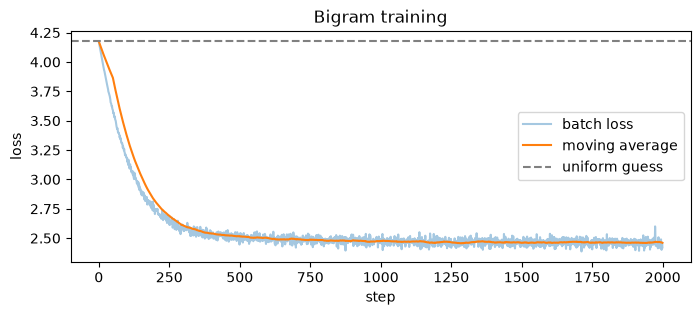

In [5]:
set_seed(1337)
bigram = BigramLM(tok.vocab_size).to(device)
optimizer = torch.optim.AdamW(bigram.parameters(), lr=1e-2)
print(f"loss of a uniform guess: ln(65) = {math.log(65):.3f}")

losses = []
for step in range(2000):
    xb, yb = data.get_batch("train", batch_size=32, block_size=64, device=device)
    logits, loss = bigram(xb, yb)          # forward pass
    optimizer.zero_grad(set_to_none=True)   # clear old gradients
    loss.backward()                         # backward pass
    optimizer.step()                        # update the table
    losses.append(loss.item())
    if step % 500 == 0:
        print(f"step {step:4d}  loss {loss.item():.3f}")

plt.figure(figsize=(8, 3))
plt.plot(losses, alpha=0.4, label="batch loss")
plt.plot([sum(losses[max(0, i-50):i+1]) / len(losses[max(0, i-50):i+1]) for i in range(len(losses))], label="moving average")
plt.axhline(math.log(65), color="gray", ls="--", label="uniform guess")
plt.xlabel("step"); plt.ylabel("loss"); plt.legend(); plt.title("Bigram training"); plt.show()

### What did it learn?

The whole bigram model is one 65×65 table. Row = current character, softmax of the row =
probabilities of the next character.

after 'q'   -> 'u' 98%, 'J' 0%, 'D' 0%, 'N' 0%, 'Z' 0%
after 'T'   -> 'h' 45%, 'o' 15%, 'E' 7%, 'I' 6%, ':' 6%
after '.'   -> '\n' 82%, ' ' 15%, "'" 1%, '-' 0%, 'W' 0%
after '\n'  -> '\n' 17%, 'T' 10%, 'A' 9%, 'I' 7%, 'W' 6%


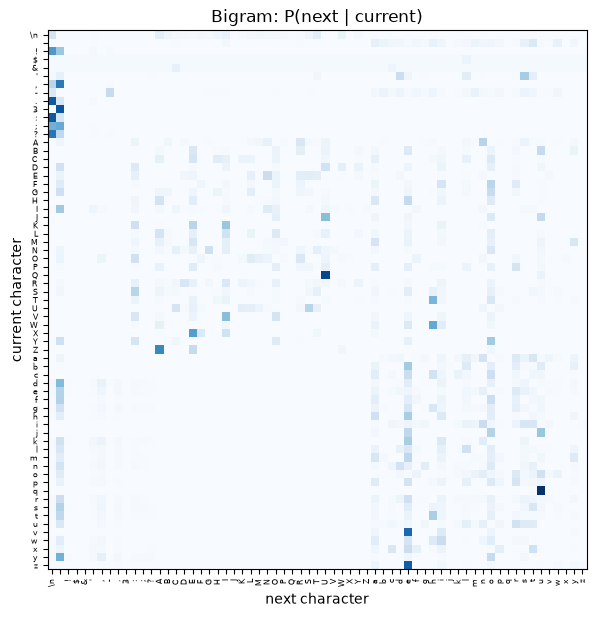

In [6]:
probs = F.softmax(bigram.token_logits.weight.detach().cpu(), dim=-1)  # (65, 65)
for ch in ["q", "T", ".", "\n"]:
    p = probs[tok.encode(ch)[0]]
    top = torch.topk(p, 5)
    nxt = ", ".join(f"{tok.decode([i])!r} {v:.0%}" for v, i in zip(top.values, top.indices))
    print(f"after {ch!r:5} -> {nxt}")

plt.figure(figsize=(7, 7))
plt.imshow(probs, cmap="Blues")
labels = [repr(tok.itos[i])[1:-1] for i in range(tok.vocab_size)]
plt.xticks(range(65), labels, fontsize=6, rotation=90); plt.yticks(range(65), labels, fontsize=6)
plt.xlabel("next character"); plt.ylabel("current character"); plt.title("Bigram: P(next | current)")
plt.show()

In [7]:
start = torch.tensor([tok.encode("\n")], device=device)
print(tok.decode(generate(bigram, start, 300)[0].tolist()))


Thaysntherelioscof thandin.
ANombed oulouel RI m.
Wid n tur go m,
T:
PENolord devirenoverden is
D t thisacas le
Heiet havenuke g h he gh cicoWhe s mimeryoursme bl t.
ThtlNDWh u it yfond es nigond atonthy
Wh I:


Anaturveloromo's.
LOULUMI ak
FiEO:

WABOn c.
ETERINTENor ch'thim s hslll y atisin m tome


Word-like chunks and plausible spacing, but no real words: one character of context
is not enough. That is what the next models fix.

## 3. One training step under the microscope

The training loop above is four lines: forward, `zero_grad`, `backward`, `step`.
Here they are taken apart on a fresh bigram model, compared with an MNIST network written from scratch in NumPy:

| step | NumPy MNIST network (by hand) | PyTorch |
|---|---|---|
| forward + loss | `forward_prop()` | `logits, loss = model(x, y)` |
| backprop | `backward_prop()`: `dZ2 = A2 - one_hot_Y` | `loss.backward()` |
| update | `update_params()`: `W1 = W1 - alpha * dW1` | `optimizer.step()` |

Runs on the CPU (small enough, and leaves the GPU to any training run in the background).

In [8]:
# A fresh, untrained bigram model and ONE small batch: 4 windows of 8 characters
set_seed(0)
model = BigramLM(tok.vocab_size)                  # weights: one 65x65 table, ~0.02 random noise
W = model.token_logits.weight                     # the table itself, shape (65, 65)
x, y = data.get_batch("train", batch_size=4, block_size=8, device="cpu")
print("input  x[0]:", repr(tok.decode(x[0])))
print("target y[0]:", repr(tok.decode(y[0])))
print("W.shape:", tuple(W.shape), "| W.grad before backward:", W.grad)

input  x[0]: 'w. Whoa,'
target y[0]: '. Whoa, '
W.shape: (65, 65) | W.grad before backward: None


### Step 1: forward pass and loss

For each of the 4 × 8 = 32 positions the model outputs 65 scores (logits). Softmax turns
them into probabilities; the loss looks only at the probability of the **correct** next
character: `-log(p_correct)`, averaged over all 32 positions.

In [9]:
logits, loss = model(x, y)                         # forward
print("logits shape:", tuple(logits.shape), "= (batch, time, vocab)")

probs = F.softmax(logits, dim=-1)                  # (4, 8, 65), every row sums to 1
print("\nfirst row of x, position by position:")
for t in range(5):
    cur, nxt = tok.decode([x[0, t]]), tok.decode([y[0, t]])
    p = probs[0, t, y[0, t]].item()
    print(f"  after {cur!r:5} correct next is {nxt!r:5}  p = {p:.4f}  -> -log(p) = {-math.log(p):.3f}")

manual_loss = -torch.log(probs.gather(-1, y.unsqueeze(-1))).mean()   # the same thing by hand
print(f"\nF.cross_entropy loss = {loss.item():.4f}   by hand = {manual_loss.item():.4f}")
print(f"untrained, so p is about 1/65 everywhere: ln(65) = {math.log(65):.4f}")

logits shape: (4, 8, 65) = (batch, time, vocab)

first row of x, position by position:
  after 'w'   correct next is '.'    p = 0.0156  -> -log(p) = 4.162
  after '.'   correct next is ' '    p = 0.0152  -> -log(p) = 4.186
  after ' '   correct next is 'W'    p = 0.0151  -> -log(p) = 4.194
  after 'W'   correct next is 'h'    p = 0.0153  -> -log(p) = 4.179
  after 'h'   correct next is 'o'    p = 0.0152  -> -log(p) = 4.189

F.cross_entropy loss = 4.1769   by hand = 4.1769
untrained, so p is about 1/65 everywhere: ln(65) = 4.1744


### Step 2: backpropagation, `loss.backward()`

Autograd walks back through every operation of the forward pass (chain rule) and stores
in `W.grad` how much the loss would change if each weight went up a little.
**Nothing is updated yet**: `W` is unchanged, only `W.grad` is filled in.

For softmax + cross-entropy the gradient has a simple form, exactly your
`dZ2 = A2 - one_hot_Y` from MNIST: **probabilities minus one-hot(correct), divided by
the number of predictions**. Let's check that autograd computes the same thing.

In [10]:
W_before = W.detach().clone()
loss.backward()                                    # backprop: fills W.grad, W itself untouched
print("W.grad shape:", tuple(W.grad.shape), "| W changed by backward?", not torch.equal(W.detach(), W_before))

# The classic formula (as in a from-scratch NumPy MNIST network), by hand: dZ = (softmax - one_hot) / N, then summed into the table row
# of each input character (an embedding lookup routes the gradient back to the row it read)
N = x.numel()                                                  # 32 predictions
dlogits = (probs.detach() - F.one_hot(y, tok.vocab_size).float()) / N   # (4, 8, 65)
manual_grad = torch.zeros_like(W)
manual_grad.index_add_(0, x.view(-1), dlogits.view(N, -1))    # add each position's grad to row x
print("autograd == (softmax - one_hot) / N ?", torch.allclose(W.grad, manual_grad, atol=1e-7))

W.grad shape: (65, 65) | W changed by backward? False
autograd == (softmax - one_hot) / N ? True


In [11]:
# Read one row of the gradient: the row of the first input character
c = x[0, 0].item()
row_grad = W.grad[c]
print(f"gradient row for current char {tok.decode([c])!r}:")
for i in torch.argsort(row_grad)[:3].tolist() + torch.argsort(row_grad)[-3:].tolist():
    sign = "negative -> gradient descent will RAISE this score" if row_grad[i] < 0 else "positive -> will LOWER it"
    print(f"   next {tok.decode([i])!r:5} grad {row_grad[i].item():+.5f}  ({sign})")
print("\nThe negative entries are exactly the characters that really followed",
      repr(tok.decode([c])), "in this batch.")

gradient row for current char 'w':
   next 'a'   grad -0.03030  (negative -> gradient descent will RAISE this score)
   next '.'   grad -0.03028  (negative -> gradient descent will RAISE this score)
   next 'U'   grad +0.00092  (positive -> will LOWER it)
   next 'r'   grad +0.00099  (positive -> will LOWER it)
   next 'k'   grad +0.00099  (positive -> will LOWER it)
   next 'J'   grad +0.00100  (positive -> will LOWER it)

The negative entries are exactly the characters that really followed 'w' in this batch.


### Step 3: the update, `optimizer.step()`

**Plain gradient descent** (SGD, what a from-scratch NumPy network does): `W = W - lr * W.grad`.
Then run the **same batch** again: the loss should be lower.

In [12]:
lr = 10.0   # big on purpose: the gradients of a 65x65 table averaged over 32 positions are tiny
sgd = torch.optim.SGD(model.parameters(), lr=lr)

expected = W.detach() - lr * W.grad                # the update, by hand
sgd.step()                                         # PyTorch's update
print("optimizer.step() == W - lr * W.grad ?", torch.allclose(W.detach(), expected))
print("largest single weight change:", (W.detach() - W_before).abs().max().item())

with torch.no_grad():
    _, loss_after = model(x, y)
print(f"loss on the same batch: before {loss.item():.4f} -> after {loss_after.item():.4f}")

optimizer.step() == W - lr * W.grad ? True
largest single weight change: 0.6110467314720154
loss on the same batch: before 4.1769 -> after 3.8226


### Step 3b: what AdamW does differently

`train.py` uses **AdamW**, not plain SGD. Same gradient, different step:

* it divides each gradient by a running average of its own size, so every weight moves
  by roughly the same amount `lr`, whether its gradient was tiny or huge
  (on the very first step: almost exactly `lr * sign(grad)`)
* momentum: later steps also follow the average of recent gradients, which smooths noisy batches
* weight decay: also pulls every weight slightly towards 0

That's why AdamW works with a "normal" learning rate like 1e-3, where SGD needed lr = 10 above.

In [13]:
set_seed(0)
model2 = BigramLM(tok.vocab_size)
W2 = model2.token_logits.weight
W2_before = W2.detach().clone()
adamw = torch.optim.AdamW(model2.parameters(), lr=1e-3, weight_decay=0.0)

_, loss2 = model2(x, y)
adamw.zero_grad(set_to_none=True)                  # clear old gradients (they'd ADD up otherwise)
loss2.backward()
adamw.step()

step = (W2.detach() - W2_before)
moved = W2.grad != 0
print("weights with a non-zero gradient:", int(moved.sum()), "of", W2.numel())
print("SGD-style step would be lr*grad, sizes ranging from",
      f"{(1e-3 * W2.grad[moved].abs()).min():.1e} to {(1e-3 * W2.grad[moved].abs()).max():.1e}")
print("AdamW's actual step sizes:", f"{step[moved].abs().min():.2e} to {step[moved].abs().max():.2e}",
      "  <- all ~1e-3 = lr")
print("step == -lr * sign(grad) ?", torch.allclose(step[moved], -1e-3 * torch.sign(W2.grad[moved]), atol=1e-6))

weights with a non-zero gradient: 975 of 4225
SGD-style step would be lr*grad, sizes ranging from 4.6e-07 to 6.1e-05
AdamW's actual step sizes: 1.00e-03 to 1.00e-03   <- all ~1e-3 = lr
step == -lr * sign(grad) ? True


### 3c. Backprop by hand: a 2 → 3 → 3 → 2 network, node by node

```
 inputs        hidden 1         hidden 2         output
  x1 ──┐     ┌─ h1_1 ──┐     ┌─ h2_1 ──┐     ┌─ o_1 ──► compare with t_1
       ├─W1──┼─ h1_2 ──┼─W2──┼─ h2_2 ──┼─W3──┤
  x2 ──┘     └─ h1_3 ──┘     └─ h2_3 ──┘     └─ o_2 ──► compare with t_2
```
Every hidden node: weighted sum `a`, then ReLU `h = max(a, 0)` with slope `σ'(a) = 1 if a > 0 else 0`.
Loss: `L = ½(o_1 − t_1)² + ½(o_2 − t_2)²`.

Two rules, applied from the output backwards (δ = "error" of a node = ∂L/∂a):
1. **weight gradient = δ of the node it feeds into × value that came into the weight**
2. **δ of a node = Σ over outgoing connections (weight × downstream δ) × its own slope σ'**

Everything below is plain Python with small numbers, so each line can be checked
on paper. At the end, PyTorch's `loss.backward()` must give exactly the same gradients.

In [14]:
# --- the network: small random weights rounded to 1 decimal, easy to follow ---
g = torch.Generator().manual_seed(18)
rnd = lambda *shape: torch.randn(*shape, generator=g, dtype=torch.float64).mul(0.8).round(decimals=1)
W1, b1 = rnd(3, 2), rnd(3)   # W1[j][i]: input i -> hidden-1 node j
W2, b2 = rnd(3, 3), rnd(3)   # W2[k][j]: hidden-1 node j -> hidden-2 node k
W3, b3 = rnd(2, 3), rnd(2)   # W3[m][k]: hidden-2 node k -> output m
x = [1.0, 2.0]               # the 2 inputs
t = [1.0, 0.0]               # the targets we want the 2 outputs to produce

for name, M in [("W1", W1), ("b1", b1), ("W2", W2), ("b2", b2), ("W3", W3), ("b3", b3)]:
    print(f"{name} =", M.tolist())
W1l, b1l, W2l, b2l, W3l, b3l = (M.tolist() for M in (W1, b1, W2, b2, W3, b3))  # plain Python lists

relu  = lambda a: max(a, 0.0)
drelu = lambda a: 1.0 if a > 0 else 0.0   # ReLU's slope

# --- forward pass, node by node ---
a1 = [W1l[j][0] * x[0] + W1l[j][1] * x[1] + b1l[j] for j in range(3)]
h1 = [relu(a) for a in a1]
a2 = [sum(W2l[k][j] * h1[j] for j in range(3)) + b2l[k] for k in range(3)]
h2 = [relu(a) for a in a2]
o  = [sum(W3l[m][k] * h2[k] for k in range(3)) + b3l[m] for m in range(2)]
L  = sum(0.5 * (o[m] - t[m]) ** 2 for m in range(2))

print("\nforward:")
for j in range(3): print(f"  hidden1 node {j+1}: a = {a1[j]:+.2f}  h = {h1[j]:.2f}")
for k in range(3): print(f"  hidden2 node {k+1}: a = {a2[k]:+.2f}  h = {h2[k]:.2f}" + ("   <- ReLU off (a <= 0)" if a2[k] <= 0 else ""))
for m in range(2): print(f"  output  node {m+1}: o = {o[m]:+.3f}  (target {t[m]})")
print(f"  loss L = {L:.4f}")

W1 = [[0.5, -0.1], [-0.6, 0.6], [-0.5, 0.5]]
b1 = [0.2, 0.5, -0.3]
W2 = [[2.1, 0.6, -0.2], [-0.4, -1.0, -1.2], [-0.5, 0.9, -0.6]]
b2 = [0.6, -1.7, 1.0]
W3 = [[-0.8, 0.3, -0.4], [-0.4, 0.8, 0.5]]
b3 = [0.2, 0.2]

forward:
  hidden1 node 1: a = +0.50  h = 0.50
  hidden1 node 2: a = +1.10  h = 1.10
  hidden1 node 3: a = +0.20  h = 0.20
  hidden2 node 1: a = +2.27  h = 2.27
  hidden2 node 2: a = -3.24  h = 0.00   <- ReLU off (a <= 0)
  hidden2 node 3: a = +1.62  h = 1.62
  output  node 1: o = -2.264  (target 1.0)
  output  node 2: o = +0.102  (target 0.0)
  loss L = 5.3321


In [15]:
# --- backward pass, node by node, printing every formula with its numbers ---
print("OUTPUT LAYER   δ3_m = o_m - t_m      (from L = ½(o - t)²,  like d(x²)/dx = 2x)")
d3 = [o[m] - t[m] for m in range(2)]
for m in range(2):
    print(f"  δ3_{m+1} = {o[m]:+.3f} - {t[m]:.1f} = {d3[m]:+.4f}")
gW3 = [[d3[m] * h2[k] for k in range(3)] for m in range(2)]   # rule 1
gb3 = d3
print("  ∂L/∂W3[m][k] = δ3_m · h2_k   e.g. ∂L/∂W3[1][1] =", f"{d3[0]:+.4f} · {h2[0]:.2f} = {gW3[0][0]:+.4f}")

print("\nHIDDEN LAYER 2   δ2_k = (δ3_1·W3[1][k] + δ3_2·W3[2][k]) · σ'(a2_k)")
dh2 = [sum(d3[m] * W3l[m][k] for m in range(2)) for k in range(3)]   # rule 2: sum over 2 outputs
d2  = [dh2[k] * drelu(a2[k]) for k in range(3)]
for k in range(3):
    print(f"  δ2_{k+1} = ({d3[0]:+.4f}·{W3l[0][k]:+.1f} + {d3[1]:+.4f}·{W3l[1][k]:+.1f}) · σ'({a2[k]:+.2f})"
          f" = {dh2[k]:+.4f} · {drelu(a2[k]):.0f} = {d2[k]:+.4f}")
gW2 = [[d2[k] * h1[j] for j in range(3)] for k in range(3)]   # rule 1
gb2 = d2

print("\nHIDDEN LAYER 1   δ1_j = (δ2_1·W2[1][j] + δ2_2·W2[2][j] + δ2_3·W2[3][j]) · σ'(a1_j)")
dh1 = [sum(d2[k] * W2l[k][j] for k in range(3)) for j in range(3)]   # sum over 3 nodes above
d1  = [dh1[j] * drelu(a1[j]) for j in range(3)]
for j in range(3):
    terms = " + ".join(f"{d2[k]:+.4f}·{W2l[k][j]:+.1f}" for k in range(3))
    print(f"  δ1_{j+1} = ({terms}) · σ'({a1[j]:+.2f}) = {d1[j]:+.4f}")
gW1 = [[d1[j] * x[i] for i in range(2)] for j in range(3)]
gb1 = d1
print("  ∂L/∂W1[j][i] = δ1_j · x_i   e.g. ∂L/∂W1[1][2] =", f"{d1[0]:+.4f} · {x[1]:.1f} = {gW1[0][1]:+.4f}")

print("\nNote: hidden2 node 2 has a <= 0, so its δ is 0 -> ALL of its incoming weights W2[2][*]"
      "\nget zero gradient, and it passes nothing back to layer 1 (a 'dead' ReLU for this input).")

OUTPUT LAYER   δ3_m = o_m - t_m      (from L = ½(o - t)²,  like d(x²)/dx = 2x)
  δ3_1 = -2.264 - 1.0 = -3.2640
  δ3_2 = +0.102 - 0.0 = +0.1020
  ∂L/∂W3[m][k] = δ3_m · h2_k   e.g. ∂L/∂W3[1][1] = -3.2640 · 2.27 = -7.4093

HIDDEN LAYER 2   δ2_k = (δ3_1·W3[1][k] + δ3_2·W3[2][k]) · σ'(a2_k)
  δ2_1 = (-3.2640·-0.8 + +0.1020·-0.4) · σ'(+2.27) = +2.5704 · 1 = +2.5704
  δ2_2 = (-3.2640·+0.3 + +0.1020·+0.8) · σ'(-3.24) = -0.8976 · 0 = -0.0000
  δ2_3 = (-3.2640·-0.4 + +0.1020·+0.5) · σ'(+1.62) = +1.3566 · 1 = +1.3566

HIDDEN LAYER 1   δ1_j = (δ2_1·W2[1][j] + δ2_2·W2[2][j] + δ2_3·W2[3][j]) · σ'(a1_j)
  δ1_1 = (+2.5704·+2.1 + -0.0000·-0.4 + +1.3566·-0.5) · σ'(+0.50) = +4.7195
  δ1_2 = (+2.5704·+0.6 + -0.0000·-1.0 + +1.3566·+0.9) · σ'(+1.10) = +2.7632
  δ1_3 = (+2.5704·-0.2 + -0.0000·-1.2 + +1.3566·-0.6) · σ'(+0.20) = -1.3280
  ∂L/∂W1[j][i] = δ1_j · x_i   e.g. ∂L/∂W1[1][2] = +4.7195 · 2.0 = +9.4391

Note: hidden2 node 2 has a <= 0, so its δ is 0 -> ALL of its incoming weights W2[2][*]
get zero gradi

In [16]:
# --- the same thing as ONE long chain-rule formula: sum over all 6 paths to the loss ---
#     ∂L/∂W1[1][1] = Σ_m Σ_k (o_m - t_m) · W3[m][k] · σ'(a2_k) · W2[k][1] · σ'(a1_1) · x_1
paths = [(o[m] - t[m]) * W3l[m][k] * drelu(a2[k]) * W2l[k][0] * drelu(a1[0]) * x[0]
         for m in range(2) for k in range(3)]
print("6 paths:", [round(p, 4) for p in paths])
print(f"sum of paths = {sum(paths):+.6f}   layer-by-layer backprop = {gW1[0][0]:+.6f}")

6 paths: [5.4835, 0.0, -0.6528, -0.0857, -0.0, -0.0255]
sum of paths = +4.719540   layer-by-layer backprop = +4.719540


In [17]:
# --- PyTorch autograd on the identical network: must match every number above ---
params = [P.clone().requires_grad_(True) for P in (W1, b1, W2, b2, W3, b3)]
tW1, tb1, tW2, tb2, tW3, tb3 = params
xt, tt = torch.tensor(x, dtype=torch.float64), torch.tensor(t, dtype=torch.float64)

h1t = torch.relu(tW1 @ xt + tb1)          # (3,)
h2t = torch.relu(tW2 @ h1t + tb2)         # (3,)
ot  = tW3 @ h2t + tb3                     # (2,)
Lt  = 0.5 * ((ot - tt) ** 2).sum()
Lt.backward()                             # autograd: all 29 gradients at once

by_hand = [gW1, gb1, gW2, gb2, gW3, gb3]
for name, P, mine in zip(["W1", "b1", "W2", "b2", "W3", "b3"], params, by_hand):
    same = torch.allclose(P.grad, torch.tensor(mine, dtype=torch.float64))
    print(f"{name}: autograd == by hand ? {same}   grad = {[[round(v, 4) for v in r] if isinstance(r, list) else round(r, 4) for r in P.grad.tolist()]}")
print(f"loss: by hand {L:.6f}, PyTorch {Lt.item():.6f}")

W1: autograd == by hand ? True   grad = [[4.7195, 9.4391], [2.7632, 5.5264], [-1.328, -2.6561]]
b1: autograd == by hand ? True   grad = [4.7195, 2.7632, -1.328]
W2: autograd == by hand ? True   grad = [[1.2852, 2.8274, 0.5141], [0.0, 0.0, 0.0], [0.6783, 1.4923, 0.2713]]
b2: autograd == by hand ? True   grad = [2.5704, 0.0, 1.3566]
W3: autograd == by hand ? True   grad = [[-7.4093, -0.0, -5.2877], [0.2315, 0.0, 0.1652]]
b3: autograd == by hand ? True   grad = [-3.264, 0.102]
loss: by hand 5.332050, PyTorch 5.332050


In [18]:
# --- and one gradient-descent step lowers the loss ---
lr = 0.1
with torch.no_grad():
    for P in params:
        P -= lr * P.grad                  # W = W - lr * dL/dW, for all 29 parameters
    h1t = torch.relu(tW1 @ xt + tb1); h2t = torch.relu(tW2 @ h1t + tb2); ot = tW3 @ h2t + tb3
    print(f"outputs {[round(v, 3) for v in ot.tolist()]}  (targets {t})")
    print(f"loss {Lt.item():.4f} -> {0.5 * ((ot - tt) ** 2).sum().item():.4f} after one step")

outputs [0.552, 0.266]  (targets [1.0, 0.0])
loss 5.3321 -> 0.1359 after one step


**Summary:** `model(x, y)` measures how wrong we are, `loss.backward()` works out which
direction each weight should move, `optimizer.step()` moves them, and `zero_grad()` clears
`.grad` for the next batch (otherwise gradients accumulate, which `train.py` uses on
purpose for gradient accumulation). Repeat 5000 times.

## 4. Compare the four models

`train.py` writes `out/<dataset>-<model>-<preset>/log.csv` with train and validation loss
at every evaluation.

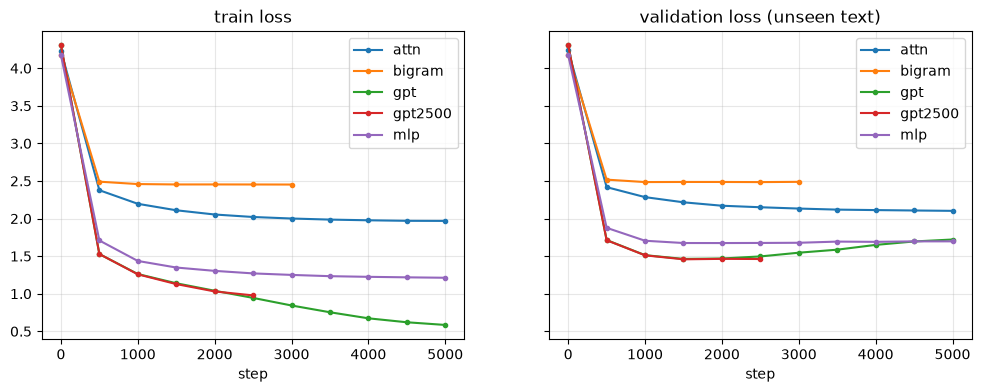

attn    best val 2.103 | final train 1.969 / val 2.103
bigram  best val 2.485 | final train 2.453 / val 2.489
gpt     best val 1.463 | final train 0.585 / val 1.721
gpt2500 best val 1.458 | final train 0.978 / val 1.462
mlp     best val 1.674 | final train 1.212 / val 1.697


In [19]:
import csv, glob

runs = {}
for path in sorted(glob.glob("out/shakespeare_char-*-mac/log.csv")):
    name = path.split("/")[1].split("-")[1]
    # strip spaces: tolerates logs whose columns were aligned in an editor
    rows = [{k.strip(): v.strip() for k, v in r.items()} for r in csv.DictReader(open(path))]
    runs[name] = rows

if not runs:
    print("no runs yet - train with: python train.py --model bigram --preset mac  (and mlp, attn, gpt)")
else:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
    for name, rows in runs.items():
        it = [int(r["iter"]) for r in rows]
        axes[0].plot(it, [float(r["train_loss"]) for r in rows], marker=".", label=name)
        axes[1].plot(it, [float(r["val_loss"]) for r in rows], marker=".", label=name)
    for ax, title in zip(axes, ["train loss", "validation loss (unseen text)"]):
        ax.set_title(title); ax.set_xlabel("step"); ax.legend(); ax.grid(alpha=0.3)
    plt.show()
    for name, rows in runs.items():
        best = min(float(r["val_loss"]) for r in rows)
        last = rows[-1]
        print(f"{name:7} best val {best:.3f} | final train {float(last['train_loss']):.3f} / val {float(last['val_loss']):.3f}")

What to look for:

* **bigram** flattens at ~2.5: it has learned everything one character of context allows.
* **mlp** (8 characters of context) is much better, but its train loss keeps falling while
  its validation loss turns back up after ~2000 steps. That gap is **overfitting**: it
  starts memorising the training text instead of learning rules that generalise.
* **attn** (one attention layer, nothing else) is *worse* than the MLP. Attention
  only *gathers* information (a weighted average of earlier tokens); with no feed-forward
  layer there is nothing that *processes* it non-linearly. That's why a transformer
  block pairs attention with an MLP.
* **gpt** stacks 6 such blocks with residual connections and LayerNorm, and it wins clearly.
  Dropout (0.2) keeps its train/val gap small.

## 5. Generate text with the trained GPT

In [20]:
import types

def load(ckpt_dir):
    from gpt import build_model
    path = f"{ckpt_dir}/best.pt" if os.path.exists(f"{ckpt_dir}/best.pt") else f"{ckpt_dir}/ckpt.pt"
    ckpt = torch.load(path, map_location=device)   # best.pt = lowest validation loss
    cfg = types.SimpleNamespace(**ckpt["config"])
    model = build_model(cfg, ckpt["vocab_size"]).to(device).eval()
    model.load_state_dict(ckpt["model"])
    print(f"{cfg.model}: {sum(p.numel() for p in model.parameters())/1e6:.2f}M params, "
          f"step {ckpt['iter']}, " + (f"val loss {ckpt['val_loss']:.3f}" if 'val_loss' in ckpt else f"best val during the run {ckpt['best_val']:.3f}"))
    return model

# prefer the 2500-step run (stops before overfitting), else the 5000-step one
gpt_dir = next((d for d in ["out/shakespeare_char-gpt2500-mac", "out/shakespeare_char-gpt-mac"]
                if os.path.exists(f"{d}/ckpt.pt")), "out/shakespeare_char-gpt-mac")
print("using", gpt_dir)
gpt_model = load(gpt_dir) if os.path.exists(f"{gpt_dir}/ckpt.pt") else None
if gpt_model is None:
    print("train it first: python train.py --model gpt --preset mac")

using out/shakespeare_char-gpt2500-mac


gpt: 10.75M params, step 1500, val loss 1.458


In [21]:
if gpt_model is not None:
    set_seed(42)
    prompt = "ROMEO:\n"
    out = generate(gpt_model, torch.tensor([tok.encode(prompt)], device=device),
                   max_new_tokens=500, temperature=0.8, top_k=50)
    print(tok.decode(out[0].tolist()))

ROMEO:
I'll be the found, and the rest,
She will indeed the tumble and night.

BENVOLIO:
What, will I wait thee, in thy brother?

MERCUTIO:
A good prince, a shapes of a fair coward
That thou hadst fall'd to have made thy brother's earth,
And thy blame, and thy brother may be gone to her will answer
That it was by then recomed by thee.

LUCIO:
Yet I shall be thine envious tongue,
Which the revenue is there in twain a dish beard
To take him his son, make for good for which I was dead;
And thou wilt prove


Try different `temperature` values (0.5 vs 1.2) and prompts. Unknown characters
(e.g. digits other than 3) raise an error: they're not in the 65-char vocabulary.

## 6. Look inside: attention weights

Each attention head produces a T×T matrix: row t = how much token t looks at each
earlier token (rows sum to 1, upper triangle is 0 because of the causal mask).
First some numbers per head, then pictures of the **first** and the **last** layer.

In [22]:
if gpt_model is not None:
    sentence = "First Citizen:\nBefore we proceed any further, hear me speak."
    idx = torch.tensor([tok.encode(sentence)], device=device)
    gpt_model.set_store_attention(True)            # keep the weights (explicit attention path)
    with torch.no_grad():
        gpt_model(idx)
    gpt_model.set_store_attention(False)
    attn = [b.attn.last_attention[0].cpu() for b in gpt_model.blocks]   # per layer: (n_head, T, T)
    T = len(sentence)

    # Three simple measurements per head, averaged over the positions of the sentence:
    #   prev  = weight on the character just before      (a "spelling" head is close to 1)
    #   first = weight on the very first token            (the "attention sink", see below)
    print("share of attention per head:   prev char           |   first token")
    for L, att in enumerate(attn):
        prev = torch.stack([att[:, t, t - 1] for t in range(1, T)], 1).mean(1)
        first = att[:, 5:, 0].mean(1)
        print(f"layer {L+1}:  {' '.join(f'{v:.2f}' for v in prev)}  |  {' '.join(f'{v:.2f}' for v in first)}")

share of attention per head:   prev char           |   first token
layer 1:  0.64 0.37 0.01 0.89 0.13 0.95  |  0.01 0.02 0.00 0.00 0.01 0.00
layer 2:  0.06 0.07 0.07 0.29 0.06 0.25  |  0.07 0.08 0.10 0.08 0.08 0.06
layer 3:  0.10 0.56 0.06 0.09 0.15 0.14  |  0.06 0.03 0.18 0.05 0.06 0.03
layer 4:  0.15 0.17 0.06 0.11 0.10 0.16  |  0.06 0.04 0.06 0.03 0.07 0.06
layer 5:  0.15 0.07 0.24 0.12 0.13 0.07  |  0.08 0.14 0.11 0.06 0.08 0.05
layer 6:  0.06 0.09 0.05 0.05 0.05 0.09  |  0.13 0.06 0.07 0.10 0.09 0.04


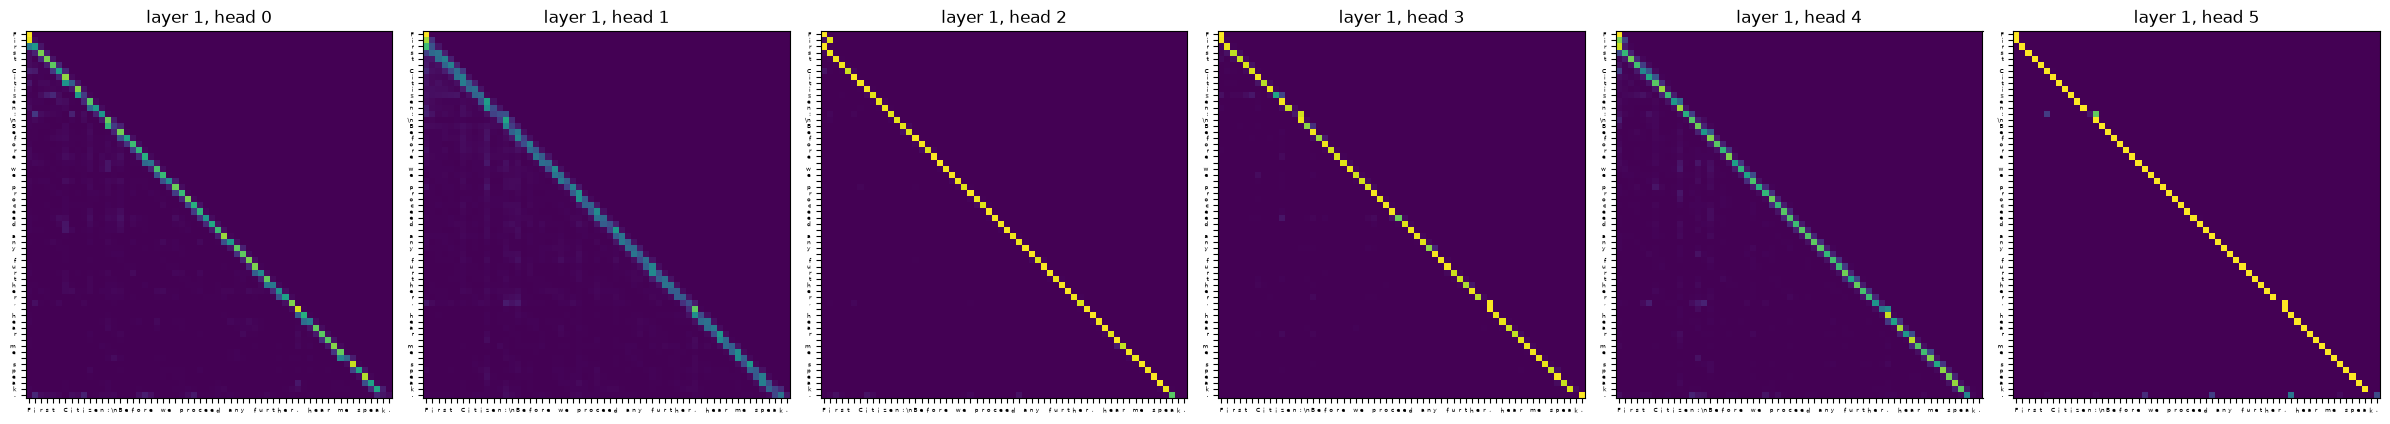

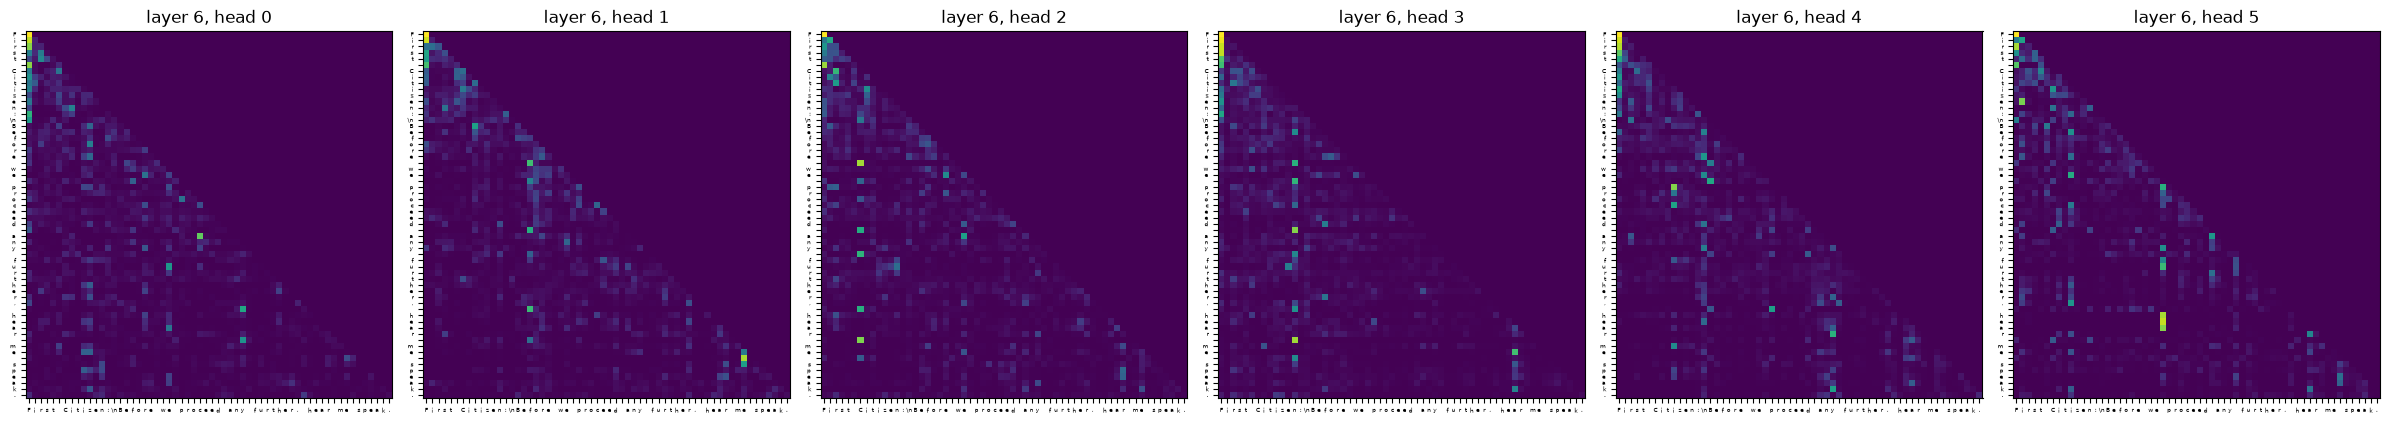

In [23]:
if gpt_model is not None:
    chars = [repr(c)[1:-1] for c in sentence]
    for L in [0, len(attn) - 1]:                    # first and last layer
        att = attn[L]
        n_head = att.shape[0]
        fig, axes = plt.subplots(1, n_head, figsize=(4 * n_head, 4.3))
        for h, ax in enumerate(axes):
            ax.imshow(att[h], cmap="viridis")
            ax.set_xticks(range(T), chars, fontsize=4)
            ax.set_yticks(range(T), chars, fontsize=4)
            ax.set_title(f"layer {L+1}, head {h}")
        plt.tight_layout(); plt.show()

What this trained model actually does (your numbers will be close if you retrain):

* **Layer 1 - "previous character" heads.** Two heads put ~95% of their attention on the
  character just before: the bright line right below the diagonal. That's the bigram
  idea again, learned by attention: the cheapest useful information is "what came just before".
  A third head splits its attention between the previous character and a few others.
* **Layers 2-3** still keep one such head each (~65%), the others start to spread out.
* **Later layers (4-6)** look diffuse: their heads combine information that earlier layers
  already gathered, so a single heatmap is hard to read.
* **Bright first column (layers 2-6): the "attention sink".** Softmax forces every row
  to sum to 1, so a head that has nothing useful to look at for some position still has
  to put its attention *somewhere*. Models learn to park it on the first token. It's a
  well-known effect in large language models too.

**Next steps:** `--dataset tinystories` (BPE tokens, real English stories), then the
`gpt2-small` preset on NVIDIA GPUs. See README.md.